Reading: C:\Users\laiba\Task 1.csv
Saving outputs to: C:\Users\laiba\task1_output

Fit results:


,phi_deg,mean_signal_a_V,sigma_a_fit_V,modulation_amplitude_R_V,sigma_R_fit_V,modulation_depth_C,sigma_C_fit,modulation_depth_theory,theta_max_deg,sigma_theta_max_fit_deg,theta_max_theory_deg,S_min_V,sigma_S_min_fit_V,S_max_V,sigma_S_max_fit_V,residual_rms_V,R_squared
0,0,1.108537,0.000782,1.104690,0.001079,0.996529,0.001159,1.0,91.714605,0.029395,90.0,0.003848,0.001286,2.213227,0.001377,0.003401,0.999985
1,30,1.133279,0.000528,0.565766,0.000758,0.499229,0.000702,0.5,122.219755,0.037198,120.0,0.567513,0.000911,1.699046,0.000937,0.002295,0.999971
2,45,1.139453,0.000291,0.057065,0.000402,0.050081,0.000354,0.0,177.168801,0.211953,NaN,1.082388,0.000513,1.196519,0.000479,0.001267,0.999207



Comparison with theoretical values:
phi = 30 degrees: S_min/I0 = 0.2564 (theory: 0.2500)
phi = 30 degrees: S_max/I0 = 0.7677 (theory: 0.7500)
phi = 45 degrees: mean signal/I0 = 0.5148 (theory: 0.5000)


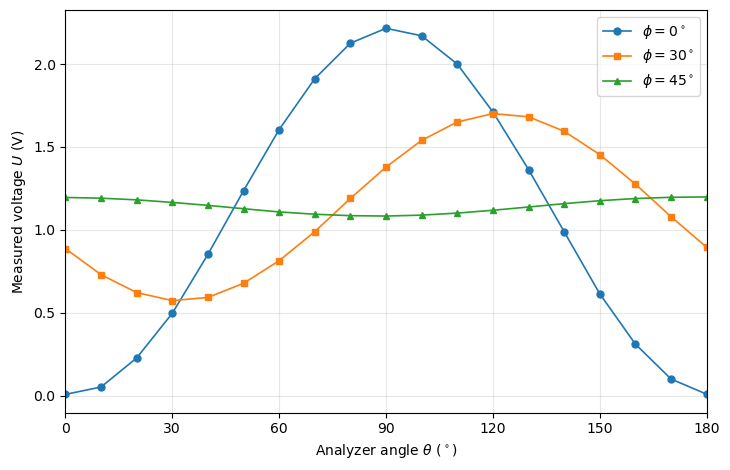

Saved: task1_output\task1_all_raw_data.png


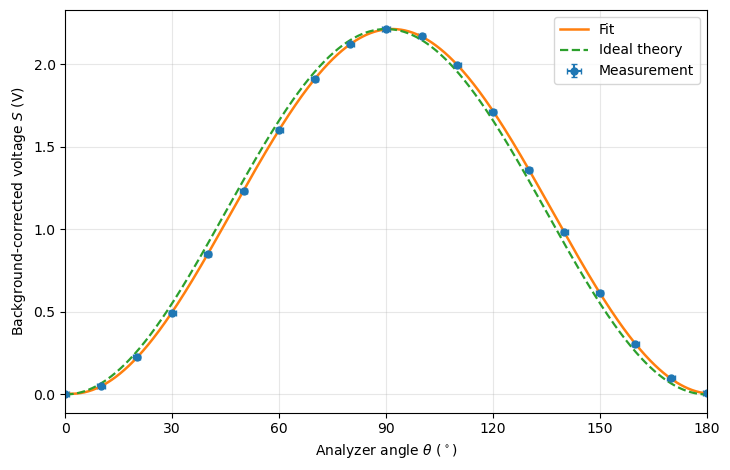

Saved: task1_output\task1_phi_0.png


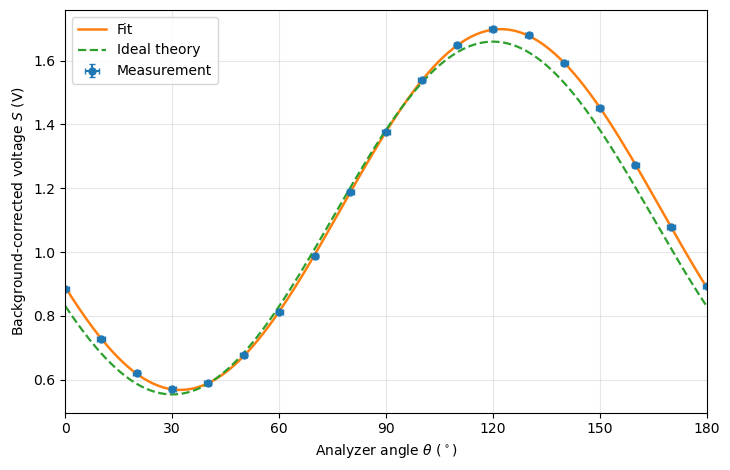

Saved: task1_output\task1_phi_30.png


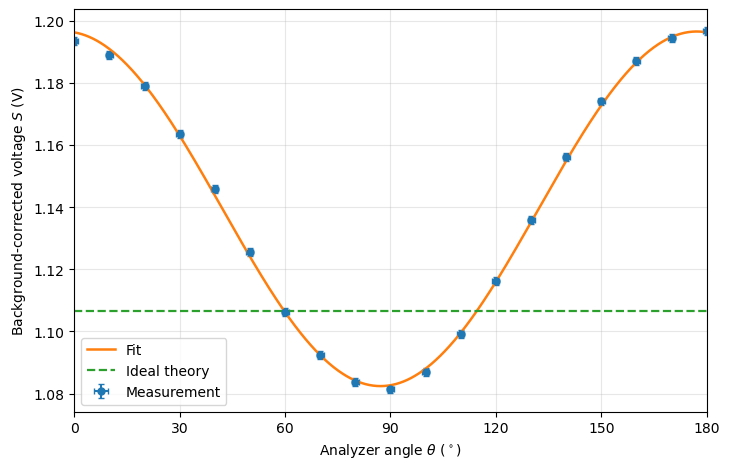

Saved: task1_output\task1_phi_45.png

Analysis complete.
Analyzer uncertainty used: 1.0 degrees
QWP uncertainty used: 2.0 degrees
The uncertainties listed in the fit-results CSV are statistical fit uncertainties only.
The residual RMS is used only as an empirical estimate of voltage scatter because repeated readings were not recorded.


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from IPython.display import display

U_BG = 0.0016          # Blocked-LED background voltage, V
SIGMA_THETA = 1.0      # Analyzer-angle uncertainty, degrees
SIGMA_PHI = 2.0        # QWP-angle uncertainty, degrees

SHOW_PHI_UNCERTAINTY_BAND = False

possible_csv_paths = [
    Path("Task 1.csv"),
    Path("/mnt/data/Task 1.csv"),
]

CSV_PATH = next(
    (path for path in possible_csv_paths if path.exists()),
    None,
)

if CSV_PATH is None:
    raise FileNotFoundError(
        "Task 1.csv was not found. Place the CSV file in the "
        "same folder as the notebook or edit CSV_PATH manually."
    )

OUTPUT_DIR = Path("task1_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Reading: {CSV_PATH.resolve()}")
print(f"Saving outputs to: {OUTPUT_DIR.resolve()}")

data = pd.read_csv(CSV_PATH)

required_columns = [
    "analyser_angle_deg",
    "voltage_phi_0_V",
    "voltage_phi_30_V",
    "voltage_phi_45_V",
]

missing_columns = [
    column for column in required_columns
    if column not in data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing CSV columns: {missing_columns}"
    )

if data[required_columns].isnull().any().any():
    raise ValueError("The CSV file contains missing values.")

theta = data["analyser_angle_deg"].to_numpy(dtype=float)

raw_voltages = {
    0: data["voltage_phi_0_V"].to_numpy(dtype=float),
    30: data["voltage_phi_30_V"].to_numpy(dtype=float),
    45: data["voltage_phi_45_V"].to_numpy(dtype=float),
}

corrected_signals = {
    phi: voltage - U_BG
    for phi, voltage in raw_voltages.items()
}

processed_data = data.copy()

for phi in [0, 30, 45]:
    processed_data[f"signal_phi_{phi}_V"] = corrected_signals[phi]

processed_data.to_csv(
    OUTPUT_DIR / "task1_processed_data.csv",
    index=False,
)

def harmonic_model(theta_deg, a, b, c):
    """
    General analyzer-angle fit:

        S(theta) = a + b cos(2 theta) + c sin(2 theta)

    theta_deg is given in degrees.
    """
    theta_rad = np.deg2rad(theta_deg)

    return (
        a
        + b * np.cos(2.0 * theta_rad)
        + c * np.sin(2.0 * theta_rad)
    )


def ideal_task1_model(theta_deg, phi_deg, i0):
    """
    Ideal Task 1 signal for the experimental convention
    alpha = 90 degrees:

        I(theta, phi)
        = I0/2 [1 - cos(2 phi) cos(2(theta - phi))]
    """
    theta_rad = np.deg2rad(theta_deg)
    phi_rad = np.deg2rad(phi_deg)

    return (
        0.5
        * i0
        * (
            1.0
            - np.cos(2.0 * phi_rad)
            * np.cos(2.0 * (theta_rad - phi_rad))
        )
    )


def propagated_uncertainty(jacobian, covariance):
    """
    Linear uncertainty propagation:

        sigma_f^2 = J Cov J^T
    """
    variance = float(
        jacobian @ covariance @ jacobian.T
    )

    return np.sqrt(max(variance, 0.0))


def fit_scan(theta_deg, signal):
    """
    Fit one analyzer scan and calculate the derived quantities.
    """

    # Initial parameter estimates
    a_initial = np.mean(signal)

    b_initial = 0.5 * (
        signal[0] - signal[len(signal) // 2]
    )

    c_initial = 0.0

    fit_parameters, covariance = curve_fit(
        harmonic_model,
        theta_deg,
        signal,
        p0=[a_initial, b_initial, c_initial],
        maxfev=10000,
    )

    a, b, c = fit_parameters

    fitted_values = harmonic_model(
        theta_deg,
        *fit_parameters,
    )

    residuals = signal - fitted_values

    degrees_of_freedom = max(
        len(signal) - len(fit_parameters),
        1,
    )

    residual_rms = np.sqrt(
        np.sum(residuals**2)
        / degrees_of_freedom
    )

    residual_sum_squares = np.sum(residuals**2)

    total_sum_squares = np.sum(
        (signal - np.mean(signal))**2
    )

    if total_sum_squares > 0:
        r_squared = (
            1.0
            - residual_sum_squares
            / total_sum_squares
        )
    else:
        r_squared = np.nan

    # Derived quantities
    R = np.hypot(b, c)

    theta_max = (
        0.5
        * np.degrees(np.arctan2(c, b))
    ) % 180.0

    signal_max = a + R
    signal_min = a - R
    modulation_depth = R / a

    parameter_uncertainties = np.sqrt(
        np.diag(covariance)
    )

    sigma_a, sigma_b, sigma_c = (
        parameter_uncertainties
    )

    # Fit-only uncertainty propagation
    if R > 0:

        jacobian_R = np.array([
            0.0,
            b / R,
            c / R,
        ])

        jacobian_theta_max = (
            np.array([
                0.0,
                -0.5 * c / R**2,
                0.5 * b / R**2,
            ])
            * 180.0
            / np.pi
        )

        jacobian_C = np.array([
            -R / a**2,
            b / (a * R),
            c / (a * R),
        ])

        jacobian_signal_max = np.array([
            1.0,
            b / R,
            c / R,
        ])

        jacobian_signal_min = np.array([
            1.0,
            -b / R,
            -c / R,
        ])

        sigma_R = propagated_uncertainty(
            jacobian_R,
            covariance,
        )

        sigma_theta_max = propagated_uncertainty(
            jacobian_theta_max,
            covariance,
        )

        sigma_C = propagated_uncertainty(
            jacobian_C,
            covariance,
        )

        sigma_signal_max = propagated_uncertainty(
            jacobian_signal_max,
            covariance,
        )

        sigma_signal_min = propagated_uncertainty(
            jacobian_signal_min,
            covariance,
        )

    else:
        sigma_R = np.nan
        sigma_theta_max = np.nan
        sigma_C = np.nan
        sigma_signal_max = np.nan
        sigma_signal_min = np.nan

    return {
        "a": a,
        "sigma_a": sigma_a,
        "b": b,
        "sigma_b": sigma_b,
        "c": c,
        "sigma_c": sigma_c,
        "R": R,
        "sigma_R": sigma_R,
        "theta_max_deg": theta_max,
        "sigma_theta_max_fit_deg": sigma_theta_max,
        "C": modulation_depth,
        "sigma_C_fit": sigma_C,
        "S_min_V": signal_min,
        "sigma_S_min_fit_V": sigma_signal_min,
        "S_max_V": signal_max,
        "sigma_S_max_fit_V": sigma_signal_max,
        "residual_rms_V": residual_rms,
        "R_squared": r_squared,
        "fit_parameters": fit_parameters,
        "covariance": covariance,
        "residuals": residuals,
    }

fit_results = {
    phi: fit_scan(theta, corrected_signals[phi])
    for phi in [0, 30, 45]
}

# The fitted maximum of the phi = 0 degree scan is used as I0.
reference_intensity = fit_results[0]["S_max_V"]

theoretical_maximum_angles = {
    0: 90.0,
    30: 120.0,
    45: np.nan,
}

summary_rows = []

for phi in [0, 30, 45]:

    result = fit_results[phi]

    theoretical_modulation = abs(
        np.cos(np.deg2rad(2.0 * phi))
    )

    summary_rows.append({
        "phi_deg": phi,
        "mean_signal_a_V": result["a"],
        "sigma_a_fit_V": result["sigma_a"],
        "modulation_amplitude_R_V": result["R"],
        "sigma_R_fit_V": result["sigma_R"],
        "modulation_depth_C": result["C"],
        "sigma_C_fit": result["sigma_C_fit"],
        "modulation_depth_theory":
            theoretical_modulation,
        "theta_max_deg": result["theta_max_deg"],
        "sigma_theta_max_fit_deg":
            result["sigma_theta_max_fit_deg"],
        "theta_max_theory_deg":
            theoretical_maximum_angles[phi],
        "S_min_V": result["S_min_V"],
        "sigma_S_min_fit_V":
            result["sigma_S_min_fit_V"],
        "S_max_V": result["S_max_V"],
        "sigma_S_max_fit_V":
            result["sigma_S_max_fit_V"],
        "residual_rms_V":
            result["residual_rms_V"],
        "R_squared":
            result["R_squared"],
    })

summary = pd.DataFrame(summary_rows)

summary.to_csv(
    OUTPUT_DIR / "task1_fit_results.csv",
    index=False,
)

print("\nFit results:")
display(summary.round(6))

phi_30_min_ratio = (
    fit_results[30]["S_min_V"]
    / reference_intensity
)

phi_30_max_ratio = (
    fit_results[30]["S_max_V"]
    / reference_intensity
)

phi_45_mean_ratio = (
    fit_results[45]["a"]
    / reference_intensity
)

print("\nComparison with theoretical values:")

print(
    f"phi = 30 degrees: S_min/I0 = "
    f"{phi_30_min_ratio:.4f} "
    f"(theory: 0.2500)"
)

print(
    f"phi = 30 degrees: S_max/I0 = "
    f"{phi_30_max_ratio:.4f} "
    f"(theory: 0.7500)"
)

print(
    f"phi = 45 degrees: mean signal/I0 = "
    f"{phi_45_mean_ratio:.4f} "
    f"(theory: 0.5000)"
)

fig, ax = plt.subplots(figsize=(7.4, 4.8))

markers = {
    0: "o",
    30: "s",
    45: "^",
}

for phi in [0, 30, 45]:
    ax.plot(
        theta,
        raw_voltages[phi],
        marker=markers[phi],
        markersize=5,
        linewidth=1.2,
        label=rf"$\phi={phi}^\circ$",
    )

ax.set_xlabel(
    r"Analyzer angle $\theta$ ($^\circ$)"
)

ax.set_ylabel(
    r"Measured voltage $U$ (V)"
)

ax.set_xlim(0, 180)
ax.set_xticks(np.arange(0, 181, 30))

ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

combined_raw_path = (
    OUTPUT_DIR / "task1_all_raw_data.png"
)

fig.savefig(
    combined_raw_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Saved: {combined_raw_path}")

theta_dense = np.linspace(
    0.0,
    180.0,
    1000,
)

for phi in [0, 30, 45]:

    signal = corrected_signals[phi]
    result = fit_results[phi]

    fitted_curve = harmonic_model(
        theta_dense,
        *result["fit_parameters"],
    )

    theoretical_curve = ideal_task1_model(
        theta_dense,
        phi,
        reference_intensity,
    )

    fig, ax = plt.subplots(figsize=(7.4, 4.8))

    # The residual RMS is used as an empirical estimate of
    # point-to-point voltage scatter because repeated voltage
    # readings were not recorded.
    ax.errorbar(
        theta,
        signal,
        xerr=SIGMA_THETA,
        yerr=result["residual_rms_V"],
        fmt="o",
        markersize=5,
        capsize=2,
        label="Measurement",
    )

    ax.plot(
        theta_dense,
        fitted_curve,
        linewidth=1.8,
        label="Fit",
    )

    ax.plot(
        theta_dense,
        theoretical_curve,
        linestyle="--",
        linewidth=1.6,
        label="Ideal theory",
    )

    # Show the effect of the stated QWP angle uncertainty.
    if SHOW_PHI_UNCERTAINTY_BAND:

        possible_phi_values = np.linspace(
            phi - SIGMA_PHI,
            phi + SIGMA_PHI,
            101,
        )

        theoretical_family = np.array([
            ideal_task1_model(
                theta_dense,
                possible_phi,
                reference_intensity,
            )
            for possible_phi in possible_phi_values
        ])

        theory_lower = theoretical_family.min(axis=0)
        theory_upper = theoretical_family.max(axis=0)

        ax.fill_between(
            theta_dense,
            theory_lower,
            theory_upper,
            alpha=0.15,
            label=(
                rf"Theory for "
                rf"$\phi={phi}^\circ\pm2^\circ$"
            ),
        )

    ax.set_xlabel(
        r"Analyzer angle $\theta$ ($^\circ$)"
    )

    ax.set_ylabel(
        r"Background-corrected voltage $S$ (V)"
    )

    ax.set_xlim(0, 180)
    ax.set_xticks(np.arange(0, 181, 30))

    ax.grid(True, alpha=0.3)
    ax.legend()

    # No plot title
    fig.tight_layout()

    output_path = (
        OUTPUT_DIR / f"task1_phi_{phi}.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    print(f"Saved: {output_path}")

print("\nAnalysis complete.")

print(
    f"Analyzer uncertainty used: "
    f"{SIGMA_THETA:.1f} degrees"
)

print(
    f"QWP uncertainty used: "
    f"{SIGMA_PHI:.1f} degrees"
)

print(
    "The uncertainties listed in the fit-results CSV are "
    "statistical fit uncertainties only."
)

print(
    "The residual RMS is used only as an empirical estimate "
    "of voltage scatter because repeated readings were not "
    "recorded."
)

Input files:
  BBB1: C:\Users\laiba\BBB1.csv
  BBB2: C:\Users\laiba\BBB2.csv
  BBB3: C:\Users\laiba\BBB3.csv

Outputs will be saved to: C:\Users\laiba\task2_output

Detailed fit results:


,black_box,scan,qwp_angle_deg,mean_signal_a_V,sigma_a_fit_V,modulation_amplitude_R_V,sigma_R_fit_V,modulation_depth_C,sigma_C_fit,theta_max_deg,sigma_theta_max_fit_deg,S_min_V,sigma_S_min_fit_V,S_max_V,sigma_S_max_fit_V,S_min_over_S_max,residual_rms_V,R_squared
0,BBB1,analyser_only,NaN,2.413485,0.001045,0.459992,0.001444,0.190593,0.000610,84.106302,0.094120,1.953492,0.001841,2.873477,0.001721,0.679836,0.004543,0.999843
1,BBB1,with_qwp,80.0,2.168103,0.000800,0.406704,0.001111,0.187585,0.000522,79.084736,0.081167,1.761399,0.001412,2.574808,0.001325,0.684089,0.003480,0.999881
2,BBB2,analyser_only,NaN,0.718357,0.000450,0.717671,0.000621,0.999044,0.001030,-4.637160,0.025998,0.000687,0.000740,1.436028,0.000793,0.000478,0.001956,0.999988
3,BBB2,with_qwp,0.0,0.649174,0.000527,0.636359,0.000726,0.980260,0.001324,-1.077860,0.034353,0.012815,0.000865,1.285533,0.000927,0.009969,0.002289,0.999979
4,BBB3,analyser_only,NaN,1.130941,0.000239,0.241159,0.000342,0.213237,0.000307,60.293523,0.039680,0.889782,0.000424,1.372100,0.000410,0.648482,0.001039,0.999968
5,BBB3,with_qwp,60.0,0.986759,0.000550,0.977069,0.000761,0.990180,0.000979,-82.421404,0.023286,0.009690,0.000969,1.963828,0.000907,0.004934,0.002390,0.999990



Classification summary:


,black_box,qwp_angle_deg,C_analyser_only,C_with_qwp,theta_max_analyser_only_deg,theta_max_with_qwp_deg,axis_shift_deg,Smin_over_Smax_analyser_only,Smin_over_Smax_with_qwp,estimated_qwp_transmission,estimated_qwp_loss_percent,classification
0,BBB1,80.0,0.190593,0.187585,84.106302,79.084736,5.021565,0.679836,0.684089,0.898329,10.167100,Mixture of linearly polarized and unpolarized ...
1,BBB2,0.0,0.999044,0.980260,-4.637160,-1.077860,3.559300,0.000478,0.009969,0.903693,9.630748,Linearly polarized light
2,BBB3,60.0,0.213237,0.990180,60.293523,-82.421404,37.285073,0.648482,0.004934,0.872511,12.748884,Elliptically polarized light



BBB1
Analyzer only:
  C = 0.1906
  theta_max = 84.11 degrees
  S_min = 1.953492 V
  S_max = 2.873477 V
  S_min/S_max = 0.679836
  residual RMS = 0.004543 V

With QWP at phi = 80 degrees:
  C = 0.1876
  theta_max = 79.08 degrees
  S_min = 1.761399 V
  S_max = 2.574808 V
  S_min/S_max = 0.684089
  residual RMS = 0.003480 V

Final classification:
  Mixture of linearly polarized and unpolarized light

BBB2
Analyzer only:
  C = 0.9990
  theta_max = -4.64 degrees
  S_min = 0.000687 V
  S_max = 1.436028 V
  S_min/S_max = 0.000478
  residual RMS = 0.001956 V

With QWP at phi = 0 degrees:
  C = 0.9803
  theta_max = -1.08 degrees
  S_min = 0.012815 V
  S_max = 1.285533 V
  S_min/S_max = 0.009969
  residual RMS = 0.002289 V

Final classification:
  Linearly polarized light

BBB3
Analyzer only:
  C = 0.2132
  theta_max = 60.29 degrees
  S_min = 0.889782 V
  S_max = 1.372100 V
  S_min/S_max = 0.648482
  residual RMS = 0.001039 V

With QWP at phi = 60 degrees:
  C = 0.9902
  theta_max = -82.42 degr

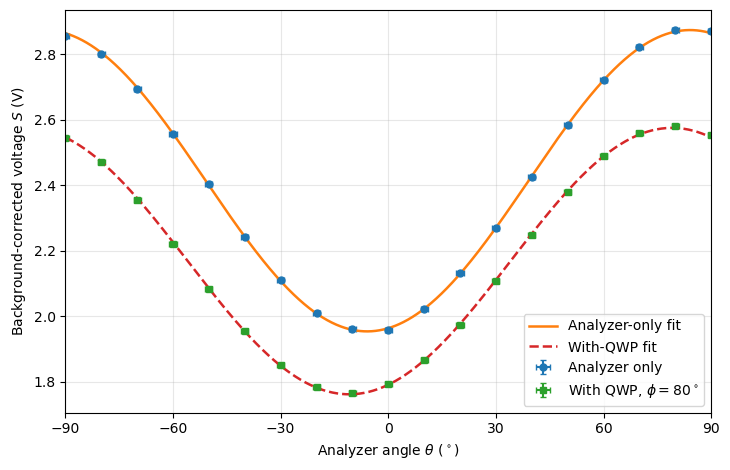

Saved: task2_output\task2_BBB1.png


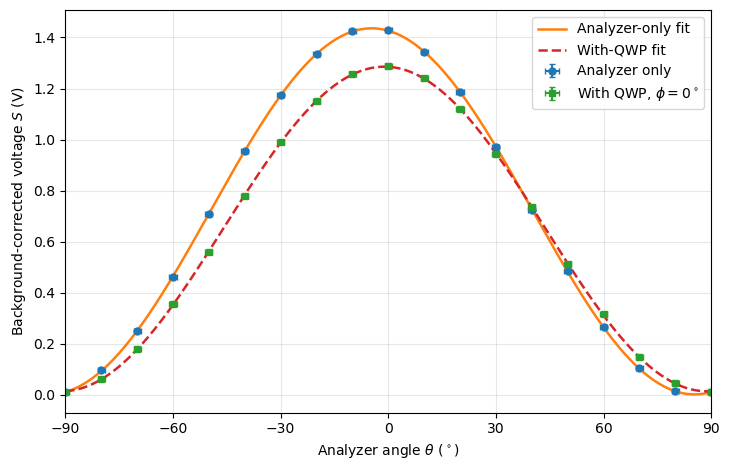

Saved: task2_output\task2_BBB2.png


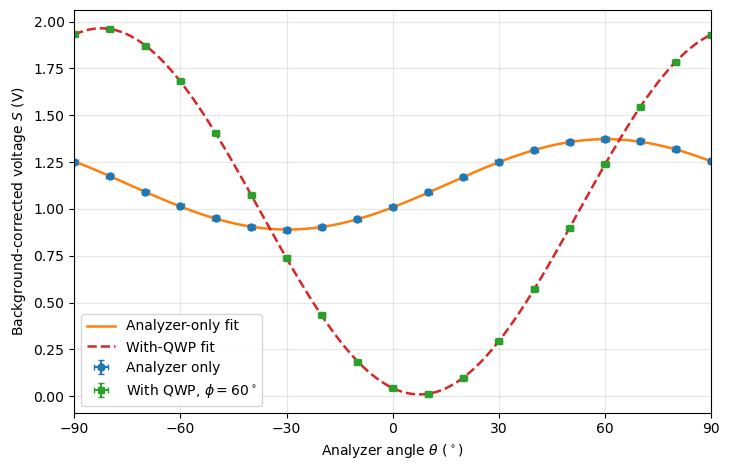

Saved: task2_output\task2_BBB3.png

Analysis complete.
Background voltage subtracted: 0.0016 V
Analyzer uncertainty used: 1.0 degrees
QWP uncertainty used: 2.0 degrees
Fit-parameter uncertainties are statistical fit uncertainties only.
The residual RMS is used as an empirical estimate of point-to-point voltage scatter because repeated readings were not recorded.


In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from IPython.display import display

U_BG = 0.0016          # Blocked-LED background voltage, V
SIGMA_THETA = 1.0      # Analyzer-angle uncertainty, degrees
SIGMA_PHI = 2.0        # QWP-angle uncertainty, degrees

file_candidates = {
    "BBB1": [
        Path("BBB1.csv"),
        Path("/mnt/data/BBB1.csv"),
    ],
    "BBB2": [
        Path("BBB2.csv"),
        Path("/mnt/data/BBB2.csv"),
    ],
    "BBB3": [
        Path("BBB3.csv"),
        Path("/mnt/data/BBB3.csv"),
    ],
}

file_paths = {}

for box, candidates in file_candidates.items():
    selected_path = next(
        (path for path in candidates if path.exists()),
        None,
    )

    if selected_path is None:
        raise FileNotFoundError(
            f"{box}.csv was not found. Place it in the same "
            "folder as the notebook or edit the file path."
        )

    file_paths[box] = selected_path

OUTPUT_DIR = Path("task2_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Input files:")
for box, path in file_paths.items():
    print(f"  {box}: {path.resolve()}")

print(f"\nOutputs will be saved to: {OUTPUT_DIR.resolve()}")

required_columns = [
    "analyser_angle_deg",
    "voltage_analyser_only_V",
    "voltage_with_qwp_V",
    "qwp_angle_deg",
]

datasets = {}

for box, path in file_paths.items():

    df = pd.read_csv(path)

    missing_columns = [
        column for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{box}.csv is missing columns: {missing_columns}"
        )

    if df[required_columns].isnull().any().any():
        raise ValueError(
            f"{box}.csv contains missing values."
        )

    qwp_angles = df["qwp_angle_deg"].unique()

    if len(qwp_angles) != 1:
        raise ValueError(
            f"{box}.csv contains more than one QWP setting: "
            f"{qwp_angles}"
        )

    theta = df[
        "analyser_angle_deg"
    ].to_numpy(dtype=float)

    voltage_analyser_only = df[
        "voltage_analyser_only_V"
    ].to_numpy(dtype=float)

    voltage_with_qwp = df[
        "voltage_with_qwp_V"
    ].to_numpy(dtype=float)

    qwp_angle = float(qwp_angles[0])

    signal_analyser_only = (
        voltage_analyser_only - U_BG
    )

    signal_with_qwp = (
        voltage_with_qwp - U_BG
    )

    datasets[box] = {
        "theta": theta,
        "voltage_analyser_only": voltage_analyser_only,
        "voltage_with_qwp": voltage_with_qwp,
        "signal_analyser_only": signal_analyser_only,
        "signal_with_qwp": signal_with_qwp,
        "qwp_angle_deg": qwp_angle,
    }

    # Save processed measurements.
    processed = df.copy()

    processed["signal_analyser_only_V"] = (
        signal_analyser_only
    )

    processed["signal_with_qwp_V"] = (
        signal_with_qwp
    )

    processed.to_csv(
        OUTPUT_DIR / f"{box}_processed.csv",
        index=False,
    )


# Confirm that all three files use the same analyzer angles.
theta_reference = datasets["BBB1"]["theta"]

for box in ["BBB2", "BBB3"]:
    if not np.array_equal(
        theta_reference,
        datasets[box]["theta"],
    ):
        raise ValueError(
            "The analyzer-angle arrays differ between files."
        )

def harmonic_model(theta_deg, a, b, c):
    """
    General analyzer-angle model:

        S(theta) = a + b cos(2 theta) + c sin(2 theta)

    The input angle is given in degrees.
    """
    theta_rad = np.deg2rad(theta_deg)

    return (
        a
        + b * np.cos(2.0 * theta_rad)
        + c * np.sin(2.0 * theta_rad)
    )


def wrap_axis_angle(angle_deg):
    """
    Express a polarization-axis direction in the interval
    [-90 degrees, +90 degrees).
    """
    return (
        (angle_deg + 90.0) % 180.0
    ) - 90.0


def axis_angle_difference(angle_1_deg, angle_2_deg):
    """
    Return the smallest absolute angular difference between
    two axes with 180-degree periodicity.
    """
    difference = (
        angle_1_deg
        - angle_2_deg
        + 90.0
    ) % 180.0 - 90.0

    return abs(difference)


def propagated_uncertainty(jacobian, covariance):
    """
    Linear uncertainty propagation:

        sigma_f^2 = J Cov J^T
    """
    variance = float(
        jacobian @ covariance @ jacobian.T
    )

    return np.sqrt(max(variance, 0.0))


def fit_scan(theta_deg, signal):
    """
    Fit one analyzer scan and calculate:
    - mean signal,
    - modulation amplitude,
    - modulation depth,
    - maximum angle,
    - fitted extrema,
    - residual RMS,
    - R-squared,
    - fit-only parameter uncertainties.
    """

    # Initial estimates
    a_initial = np.mean(signal)

    b_initial = 0.5 * (
        signal[0] - signal[len(signal) // 2]
    )

    c_initial = 0.0

    fit_parameters, covariance = curve_fit(
        harmonic_model,
        theta_deg,
        signal,
        p0=[
            a_initial,
            b_initial,
            c_initial,
        ],
        maxfev=10000,
    )

    a, b, c = fit_parameters

    fitted_values = harmonic_model(
        theta_deg,
        *fit_parameters,
    )

    residuals = signal - fitted_values

    degrees_of_freedom = max(
        len(signal) - len(fit_parameters),
        1,
    )

    residual_rms = np.sqrt(
        np.sum(residuals**2)
        / degrees_of_freedom
    )

    residual_sum_squares = np.sum(
        residuals**2
    )

    total_sum_squares = np.sum(
        (signal - np.mean(signal))**2
    )

    if total_sum_squares > 0:
        r_squared = (
            1.0
            - residual_sum_squares
            / total_sum_squares
        )
    else:
        r_squared = np.nan

    # Derived fit quantities
    R = np.hypot(b, c)

    theta_max = wrap_axis_angle(
        0.5
        * np.degrees(
            np.arctan2(c, b)
        )
    )

    signal_max = a + R
    signal_min = a - R

    modulation_depth = R / a

    if signal_max != 0:
        minimum_ratio = signal_min / signal_max
    else:
        minimum_ratio = np.nan

    parameter_uncertainties = np.sqrt(
        np.diag(covariance)
    )

    sigma_a, sigma_b, sigma_c = (
        parameter_uncertainties
    )

    # Fit-only uncertainty propagation
    if R > 0:

        jacobian_R = np.array([
            0.0,
            b / R,
            c / R,
        ])

        jacobian_theta_max = (
            np.array([
                0.0,
                -0.5 * c / R**2,
                0.5 * b / R**2,
            ])
            * 180.0
            / np.pi
        )

        jacobian_C = np.array([
            -R / a**2,
            b / (a * R),
            c / (a * R),
        ])

        jacobian_signal_max = np.array([
            1.0,
            b / R,
            c / R,
        ])

        jacobian_signal_min = np.array([
            1.0,
            -b / R,
            -c / R,
        ])

        sigma_R = propagated_uncertainty(
            jacobian_R,
            covariance,
        )

        sigma_theta_max = propagated_uncertainty(
            jacobian_theta_max,
            covariance,
        )

        sigma_C = propagated_uncertainty(
            jacobian_C,
            covariance,
        )

        sigma_signal_max = propagated_uncertainty(
            jacobian_signal_max,
            covariance,
        )

        sigma_signal_min = propagated_uncertainty(
            jacobian_signal_min,
            covariance,
        )

    else:
        sigma_R = np.nan
        sigma_theta_max = np.nan
        sigma_C = np.nan
        sigma_signal_max = np.nan
        sigma_signal_min = np.nan

    return {
        "a": a,
        "sigma_a_fit": sigma_a,
        "b": b,
        "sigma_b_fit": sigma_b,
        "c": c,
        "sigma_c_fit": sigma_c,
        "R": R,
        "sigma_R_fit": sigma_R,
        "C": modulation_depth,
        "sigma_C_fit": sigma_C,
        "theta_max_deg": theta_max,
        "sigma_theta_max_fit_deg": sigma_theta_max,
        "S_min_V": signal_min,
        "sigma_S_min_fit_V": sigma_signal_min,
        "S_max_V": signal_max,
        "sigma_S_max_fit_V": sigma_signal_max,
        "S_min_over_S_max": minimum_ratio,
        "residual_rms_V": residual_rms,
        "R_squared": r_squared,
        "fit_parameters": fit_parameters,
        "residuals": residuals,
    }

fit_results = {}

for box in ["BBB1", "BBB2", "BBB3"]:

    fit_results[box] = {
        "analyser_only": fit_scan(
            datasets[box]["theta"],
            datasets[box]["signal_analyser_only"],
        ),
        "with_qwp": fit_scan(
            datasets[box]["theta"],
            datasets[box]["signal_with_qwp"],
        ),
    }

fit_rows = []

for box in ["BBB1", "BBB2", "BBB3"]:

    qwp_angle = datasets[box]["qwp_angle_deg"]

    for scan_name in [
        "analyser_only",
        "with_qwp",
    ]:

        result = fit_results[box][scan_name]

        fit_rows.append({
            "black_box": box,
            "scan": scan_name,
            "qwp_angle_deg": (
                np.nan
                if scan_name == "analyser_only"
                else qwp_angle
            ),
            "mean_signal_a_V": result["a"],
            "sigma_a_fit_V": result["sigma_a_fit"],
            "modulation_amplitude_R_V": result["R"],
            "sigma_R_fit_V": result["sigma_R_fit"],
            "modulation_depth_C": result["C"],
            "sigma_C_fit": result["sigma_C_fit"],
            "theta_max_deg": result["theta_max_deg"],
            "sigma_theta_max_fit_deg":
                result["sigma_theta_max_fit_deg"],
            "S_min_V": result["S_min_V"],
            "sigma_S_min_fit_V":
                result["sigma_S_min_fit_V"],
            "S_max_V": result["S_max_V"],
            "sigma_S_max_fit_V":
                result["sigma_S_max_fit_V"],
            "S_min_over_S_max":
                result["S_min_over_S_max"],
            "residual_rms_V":
                result["residual_rms_V"],
            "R_squared":
                result["R_squared"],
        })

fit_table = pd.DataFrame(fit_rows)

fit_table.to_csv(
    OUTPUT_DIR / "task2_fit_results.csv",
    index=False,
)

print("\nDetailed fit results:")
display(fit_table.round(6))

classifications = {
    "BBB1": (
        "Mixture of linearly polarized "
        "and unpolarized light"
    ),
    "BBB2": "Linearly polarized light",
    "BBB3": "Elliptically polarized light",
}

summary_rows = []

for box in ["BBB1", "BBB2", "BBB3"]:

    analyser_only = fit_results[box][
        "analyser_only"
    ]

    with_qwp = fit_results[box][
        "with_qwp"
    ]

    qwp_angle = datasets[box][
        "qwp_angle_deg"
    ]

    qwp_transmission = (
        with_qwp["a"]
        / analyser_only["a"]
    )

    qwp_loss_percent = (
        1.0 - qwp_transmission
    ) * 100.0

    maximum_axis_shift = axis_angle_difference(
        analyser_only["theta_max_deg"],
        with_qwp["theta_max_deg"],
    )

    summary_rows.append({
        "black_box": box,
        "qwp_angle_deg": qwp_angle,
        "C_analyser_only":
            analyser_only["C"],
        "C_with_qwp":
            with_qwp["C"],
        "theta_max_analyser_only_deg":
            analyser_only["theta_max_deg"],
        "theta_max_with_qwp_deg":
            with_qwp["theta_max_deg"],
        "axis_shift_deg":
            maximum_axis_shift,
        "Smin_over_Smax_analyser_only":
            analyser_only["S_min_over_S_max"],
        "Smin_over_Smax_with_qwp":
            with_qwp["S_min_over_S_max"],
        "estimated_qwp_transmission":
            qwp_transmission,
        "estimated_qwp_loss_percent":
            qwp_loss_percent,
        "classification":
            classifications[box],
    })

classification_summary = pd.DataFrame(
    summary_rows
)

classification_summary.to_csv(
    OUTPUT_DIR
    / "task2_classification_summary.csv",
    index=False,
)

print("\nClassification summary:")
display(classification_summary.round(6))

for box in ["BBB1", "BBB2", "BBB3"]:

    analyser_only = fit_results[box][
        "analyser_only"
    ]

    with_qwp = fit_results[box][
        "with_qwp"
    ]

    qwp_angle = datasets[box][
        "qwp_angle_deg"
    ]

    print("\n" + "=" * 60)
    print(box)
    print("=" * 60)

    print(
        "Analyzer only:"
        f"\n  C = {analyser_only['C']:.4f}"
        f"\n  theta_max = "
        f"{analyser_only['theta_max_deg']:.2f} degrees"
        f"\n  S_min = "
        f"{analyser_only['S_min_V']:.6f} V"
        f"\n  S_max = "
        f"{analyser_only['S_max_V']:.6f} V"
        f"\n  S_min/S_max = "
        f"{analyser_only['S_min_over_S_max']:.6f}"
        f"\n  residual RMS = "
        f"{analyser_only['residual_rms_V']:.6f} V"
    )

    print(
        f"\nWith QWP at phi = {qwp_angle:.0f} degrees:"
        f"\n  C = {with_qwp['C']:.4f}"
        f"\n  theta_max = "
        f"{with_qwp['theta_max_deg']:.2f} degrees"
        f"\n  S_min = "
        f"{with_qwp['S_min_V']:.6f} V"
        f"\n  S_max = "
        f"{with_qwp['S_max_V']:.6f} V"
        f"\n  S_min/S_max = "
        f"{with_qwp['S_min_over_S_max']:.6f}"
        f"\n  residual RMS = "
        f"{with_qwp['residual_rms_V']:.6f} V"
    )

    print(
        "\nFinal classification:"
        f"\n  {classifications[box]}"
    )

theta_dense = np.linspace(
    -90.0,
    90.0,
    1000,
)

for box in ["BBB1", "BBB2", "BBB3"]:

    data_box = datasets[box]

    analyser_only = fit_results[box][
        "analyser_only"
    ]

    with_qwp = fit_results[box][
        "with_qwp"
    ]

    qwp_angle = data_box["qwp_angle_deg"]

    analyser_only_fit = harmonic_model(
        theta_dense,
        *analyser_only["fit_parameters"],
    )

    with_qwp_fit = harmonic_model(
        theta_dense,
        *with_qwp["fit_parameters"],
    )

    fig, ax = plt.subplots(
        figsize=(7.4, 4.8)
    )

    # Analyzer-only measurements
    ax.errorbar(
        data_box["theta"],
        data_box["signal_analyser_only"],
        xerr=SIGMA_THETA,
        yerr=analyser_only["residual_rms_V"],
        fmt="o",
        markersize=5,
        capsize=2,
        label="Analyzer only",
    )

    ax.plot(
        theta_dense,
        analyser_only_fit,
        linewidth=1.8,
        label="Analyzer-only fit",
    )

    # Measurements with the QWP
    ax.errorbar(
        data_box["theta"],
        data_box["signal_with_qwp"],
        xerr=SIGMA_THETA,
        yerr=with_qwp["residual_rms_V"],
        fmt="s",
        markersize=5,
        capsize=2,
        label=(
            rf"With QWP, "
            rf"$\phi={qwp_angle:.0f}^\circ$"
        ),
    )

    ax.plot(
        theta_dense,
        with_qwp_fit,
        linewidth=1.8,
        linestyle="--",
        label="With-QWP fit",
    )

    ax.set_xlabel(
        r"Analyzer angle $\theta$ ($^\circ$)"
    )

    ax.set_ylabel(
        r"Background-corrected voltage $S$ (V)"
    )

    ax.set_xlim(-90, 90)

    ax.set_xticks(
        np.arange(-90, 91, 30)
    )

    ax.grid(
        True,
        alpha=0.3,
    )

    ax.legend()

    # No plot title
    fig.tight_layout()

    output_path = (
        OUTPUT_DIR / f"task2_{box}.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    print(f"Saved: {output_path}")

print("\nAnalysis complete.")

print(
    f"Background voltage subtracted: "
    f"{U_BG:.4f} V"
)

print(
    f"Analyzer uncertainty used: "
    f"{SIGMA_THETA:.1f} degrees"
)

print(
    f"QWP uncertainty used: "
    f"{SIGMA_PHI:.1f} degrees"
)

print(
    "Fit-parameter uncertainties are statistical fit "
    "uncertainties only."
)

print(
    "The residual RMS is used as an empirical estimate of "
    "point-to-point voltage scatter because repeated readings "
    "were not recorded."
)